# Breast Cancer Classification: Model Evaluation

## Project Overview

In this notebook, we will prepare the Breast Cancer Wisconsin (Diagnostic) dataset and evaluate five classification models on the same held-out test set. The goal is to predict whether a tumor is **malignant** or **benign**, then compare model performance using consistent evaluation metrics.

The working dataset contains 569 observations and 30 numeric features. The numeric `target` is encoded as `1` for malignant and `0` for benign; `diagnosis` is a readable label used for exploration.

## Workflow

1. Load the dataset and inspect its structure, target distribution, missing values, and duplicate records.
2. Prepare the features and target, excluding any non-predictive identifier columns.
3. Create a stratified training and test split so both sets preserve the class distribution.
4. Scale features where needed, fitting preprocessing steps on the training data only to avoid data leakage.
5. Train Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes, and Support Vector Machine classifiers using the same split.
6. Evaluate each model using accuracy, AUC, precision, recall, F1 score, and Matthews correlation coefficient (MCC).
7. Compare the measured results, discuss each model, and identify the strongest performer based on the evaluation data.
8. Save the trained models and preprocessing artifact for later use in the Streamlit application, and prepare the held-out test data for app evaluation.

All reported metrics and conclusions will be based on model outputs produced in this notebook; no values will be assumed in advance.

## Dataset Source and Description

- **Dataset:** Breast Cancer Wisconsin (Diagnostic)
- **Original source:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic)
- **Citation:** Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)*. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B
- **Access method:** Loaded from scikit-learn's bundled copy with `load_breast_cancer(as_frame=True)`; this does not download the data from UCI at runtime.
- **Task:** Binary classification of tumor diagnosis as malignant or benign.
- **Size:** 569 observations and 30 numeric predictive features.
- **Feature description:** The 30 features are computed from digitized fine-needle aspirate images. They describe ten cell-nuclei measurements (including radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension), each represented by its mean, standard error, and worst value.
- **Target encoding:** `1` = malignant; `0` = benign.
- **Preprocessing:** Use the 30 numeric features as inputs, exclude the numeric target and display-only `diagnosis` label, check for missing and duplicate records, use a stratified 80/20 split, and fit `StandardScaler` on the training data only.

In [1]:
# Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context('talk')

print('Libraries imported successfully.')

Libraries imported successfully.


In [8]:
# Load the Breast Cancer Wisconsin (Diagnostic) dataset from scikit-learn
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df['target'] = (data.target == 0).astype(int)
df['diagnosis'] = df['target'].map({1: 'Malignant', 0: 'Benign'})

print(f'Dataset shape: {df.shape}')
print(f'Number of features: {df.shape[1] - 2}')
print(f'Number of samples: {df.shape[0]}')

print('\nTarget mapping: 1 = Malignant, 0 = Benign')
df.head()

Dataset shape: (569, 32)
Number of features: 30
Number of samples: 569

Target mapping: 1 = Malignant, 0 = Benign


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1,Malignant


Column names preview:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension']
...
['worst concave points', 'worst symmetry', 'worst fractal dimension', 'target', 'diagnosis']

Target distribution (1 = Malignant, 0 = Benign):
target
Benign       357
Malignant    212
Name: count, dtype: int64

Missing values:
0

Duplicate rows:
0

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    

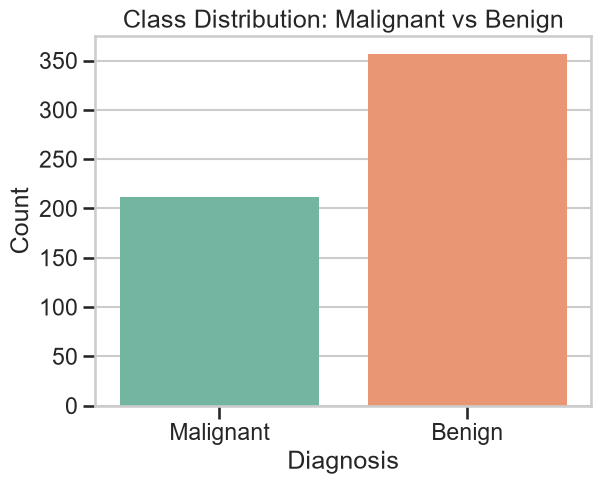

In [9]:
# Data exploration and target distribution
print('Column names preview:')
print(df.columns[:10].tolist())
print('...')
print(df.columns[-5:].tolist())

print('\nTarget distribution (1 = Malignant, 0 = Benign):')
print(df['target'].value_counts().rename(index={1: 'Malignant', 0: 'Benign'}))

print('\nMissing values:')
print(df.isnull().sum().sum())

print('\nDuplicate rows:')
print(df.duplicated().sum())

print('\nDataset information:')
df.info()

sns.countplot(data=df, x='diagnosis', hue='diagnosis', palette='Set2', legend=False)
plt.title('Class Distribution: Malignant vs Benign')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()

In [10]:
# Prepare feature matrix and target vector
feature_cols = [col for col in df.columns if col not in ['target', 'diagnosis']]
X = df[feature_cols]
y = df['target']

print(f'Features used: {len(feature_cols)}')
print(f'First feature name: {feature_cols[0]}')
print(f'Last feature name: {feature_cols[-1]}')

X.head()

Features used: 30
First feature name: mean radius
Last feature name: worst fractal dimension


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [11]:
# Train/test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f'Train set shape: {X_train.shape}')
print(f'Test set shape: {X_test.shape}')

# Standardize features using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save the scaler for future inference consistency
model_dir = Path('model')
model_dir.mkdir(exist_ok=True)
joblib.dump(scaler, model_dir / 'scaler.joblib')

print('Scaling complete and scaler saved to model/scaler.joblib')

Train set shape: (455, 30)
Test set shape: (114, 30)
Scaling complete and scaler saved to model/scaler.joblib


In [12]:
# Create a reusable evaluation function
def evaluate_model(model_name, model, X_train_scaled, y_train, X_test_scaled, y_test):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    # Use scores for class 1, which is malignant, when calculating AUC.
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_prob = model.decision_function(X_test_scaled)
    else:
        y_prob = y_pred
    
    # Positive-class precision, recall, and F1 focus on malignant cases (target 1).
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_prob),
        'Precision': precision_score(y_test, y_pred, pos_label=1),
        'Recall': recall_score(y_test, y_pred, pos_label=1),
        'F1': f1_score(y_test, y_pred, pos_label=1),
        'MCC': matthews_corrcoef(y_test, y_pred),
    }
    return metrics, model